In [1]:
##USE conda environment tf
# conda activate tf
import anndata as ad
import scanpy as sc
from matplotlib import rcParams
import pandas as pd
import h5py
import IPython
import bardensr.plotting
import numpy as np
import SimpleITK as sitk
import numpy as np
import tensorflow as tf
import bardensr.preprocessing
import harmonypy

2026-07-25 16:33:12.602077: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-07-25 16:33:12.616065: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1785011592.633506 1500928 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1785011592.638835 1500928 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-07-25 16:33:12.656918: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instr

In [2]:
import numpy as np

def rotate_points(spatial, theta):
    # Define the rotation matrix
    rotation_matrix = np.array([
        [np.cos(theta), -np.sin(theta)],
        [np.sin(theta), np.cos(theta)]
    ])
    
    # Rotate the points
    rotated_points = spatial @ rotation_matrix.T
    
    return rotated_points

# Example usage
# Create a set of points (for example)
spatial = np.array([[1, 0], [0, 1], [-1, 0], [0, -1]])

# Define the rotation angle (in radians)
theta = np.pi / 4  # 45 degrees

# Rotate the points
rotated_spatial = rotate_points(spatial, theta)
print(rotated_spatial)

[[ 0.70710678  0.70710678]
 [-0.70710678  0.70710678]
 [-0.70710678 -0.70710678]
 [ 0.70710678 -0.70710678]]


/tmp/ipykernel_1500928/3202726513.py:19: ImplicitModificationWarning: Setting element `.obsm['spatial3d']` of view, initializing view as actual.
  e15_1_corr.obsm['spatial3d'] = np.zeros([len(e15_1_corr),3])


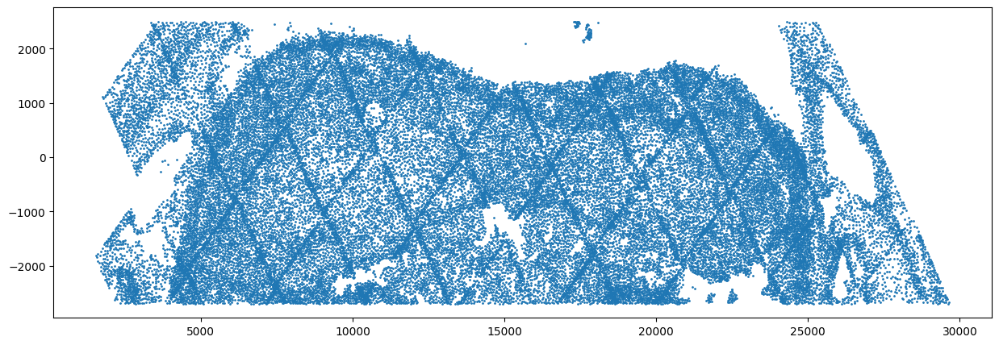

In [3]:
import matplotlib.pyplot as plt

e15_1 = ad.read_h5ad("../../../mouse/e15/ma39_e15_a4/output/adata.h5ad")
e15_1.obs['library_id'] = 'e15_1'
e15_1.obs['timepoint'] = 'e15'
e15_1.obs['batch'] = 'batch2'

e15_1.obsm['spatial'] = rotate_points(e15_1.obsm['spatial'], (-52/180)*3.14)
e15_1_coor = e15_1.obsm['spatial'][e15_1.obsm['spatial'][:,1] <2500]
e15_1_coor = e15_1_coor[e15_1_coor[:,1] >-2700]
plt.figure(figsize = (15,5))
plt.scatter(e15_1_coor[:,0], e15_1_coor[:,1], s=1)

# Convert e13_1_coor to a list of tuples for faster lookups
e15_1_coor_set = {tuple(coord) for coord in e15_1_coor}
mask = np.array([tuple(coord) in e15_1_coor_set for coord in e15_1.obsm['spatial']])
e15_1_corr = e15_1[mask]

e15_1_corr.obsm['spatial3d'] = np.zeros([len(e15_1_corr),3])
x = e15_1_corr.obsm['spatial'][:,0]
y = e15_1_corr.obsm['spatial'][:,1]
e15_1_corr.obsm['spatial'][:,0] = (x - np.min(x))
e15_1_corr.obsm['spatial'][:,1] = (y - np.min(y))

/tmp/ipykernel_1500928/985048239.py:18: ImplicitModificationWarning: Setting element `.obsm['spatial3d']` of view, initializing view as actual.
  e15_2_corr.obsm['spatial3d'] = np.zeros([len(e15_2_corr),3])


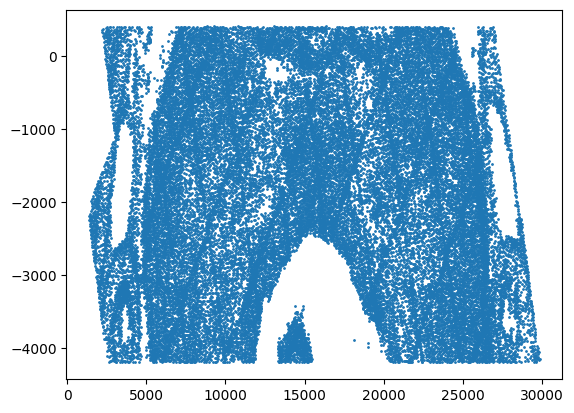

In [4]:
import matplotlib.pyplot as plt

e15_2 = ad.read_h5ad("../../../mouse/e15/ma39_e15_b2/output/adata.h5ad")
e15_2.obs['library_id'] = 'e15_2'
e15_2.obs['timepoint'] = 'e15'
e15_2.obs['batch'] = 'batch2'

e15_2.obsm['spatial'] = rotate_points(e15_2.obsm['spatial'], (-60/180)*3.14)
e15_2_coor = e15_2.obsm['spatial'][e15_2.obsm['spatial'][:,1] <400]
e15_2_coor = e15_2_coor[e15_2_coor[:,1] >-4200]
plt.scatter(e15_2_coor[:,0], e15_2_coor[:,1], s=1)

# Convert e13_1_coor to a list of tuples for faster lookups
e15_2_coor_set = {tuple(coord) for coord in e15_2_coor}
mask = np.array([tuple(coord) in e15_2_coor_set for coord in e15_2.obsm['spatial']])
e15_2_corr = e15_2[mask]

e15_2_corr.obsm['spatial3d'] = np.zeros([len(e15_2_corr),3])
x = e15_2_corr.obsm['spatial'][:,0]
y = e15_2_corr.obsm['spatial'][:,1]
e15_2_corr.obsm['spatial'][:,0] = (x - np.min(x))
e15_2_corr.obsm['spatial'][:,1] = (y - np.min(y))#+ 10000

/tmp/ipykernel_1500928/1356995397.py:18: ImplicitModificationWarning: Setting element `.obsm['spatial3d']` of view, initializing view as actual.
  e15_3_corr.obsm['spatial3d'] = np.zeros([len(e15_3_corr),3])


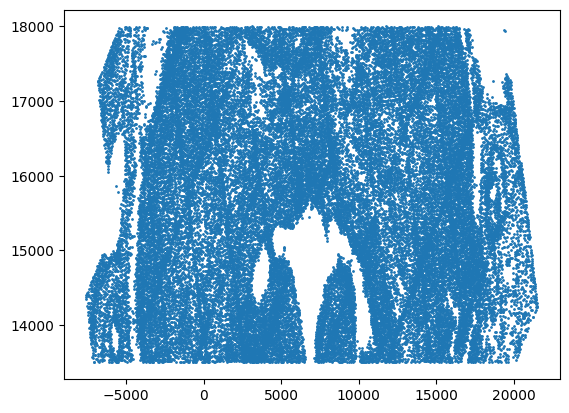

In [5]:
import matplotlib.pyplot as plt

e15_3 = ad.read_h5ad("../../../mouse/e15/ma39_e15_b3/output/adata.h5ad")
e15_3.obs['library_id'] = 'e15_3'
e15_3.obs['timepoint'] = 'e15'
e15_3.obs['batch'] = 'batch2'

e15_3.obsm['spatial'] = rotate_points(e15_3.obsm['spatial'], (28/180)*3.14)
e15_3_coor = e15_3.obsm['spatial'][e15_3.obsm['spatial'][:,1] <18000]
e15_3_coor = e15_3_coor[e15_3_coor[:,1] >13500]
plt.scatter(e15_3_coor[:,0], e15_3_coor[:,1], s=1)

# Convert e13_1_coor to a list of tuples for faster lookups
e15_3_coor_set = {tuple(coord) for coord in e15_3_coor}
mask = np.array([tuple(coord) in e15_3_coor_set for coord in e15_3.obsm['spatial']])
e15_3_corr = e15_3[mask]

e15_3_corr.obsm['spatial3d'] = np.zeros([len(e15_3_corr),3])
x = e15_3_corr.obsm['spatial'][:,0]
y = e15_3_corr.obsm['spatial'][:,1]
e15_3_corr.obsm['spatial'][:,0] = (x - np.min(x))
e15_3_corr.obsm['spatial'][:,1] = (y - np.min(y))#+ 10000*2

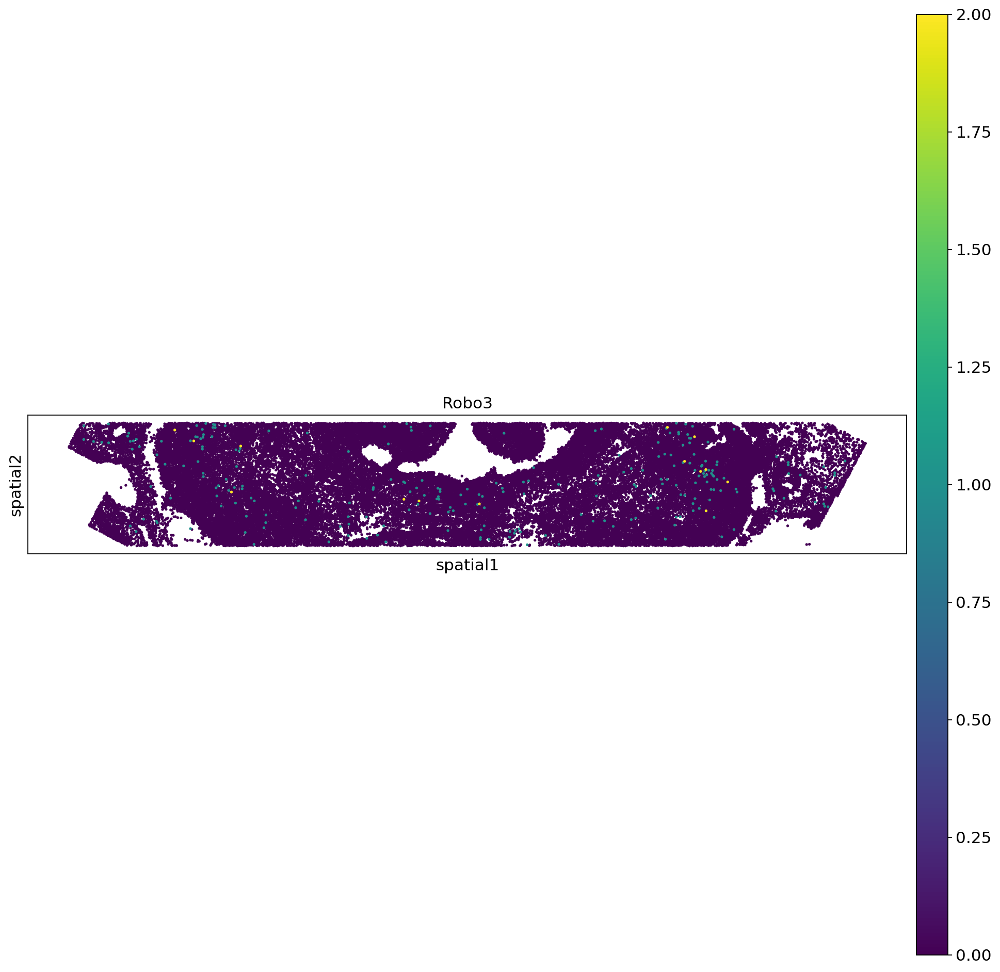

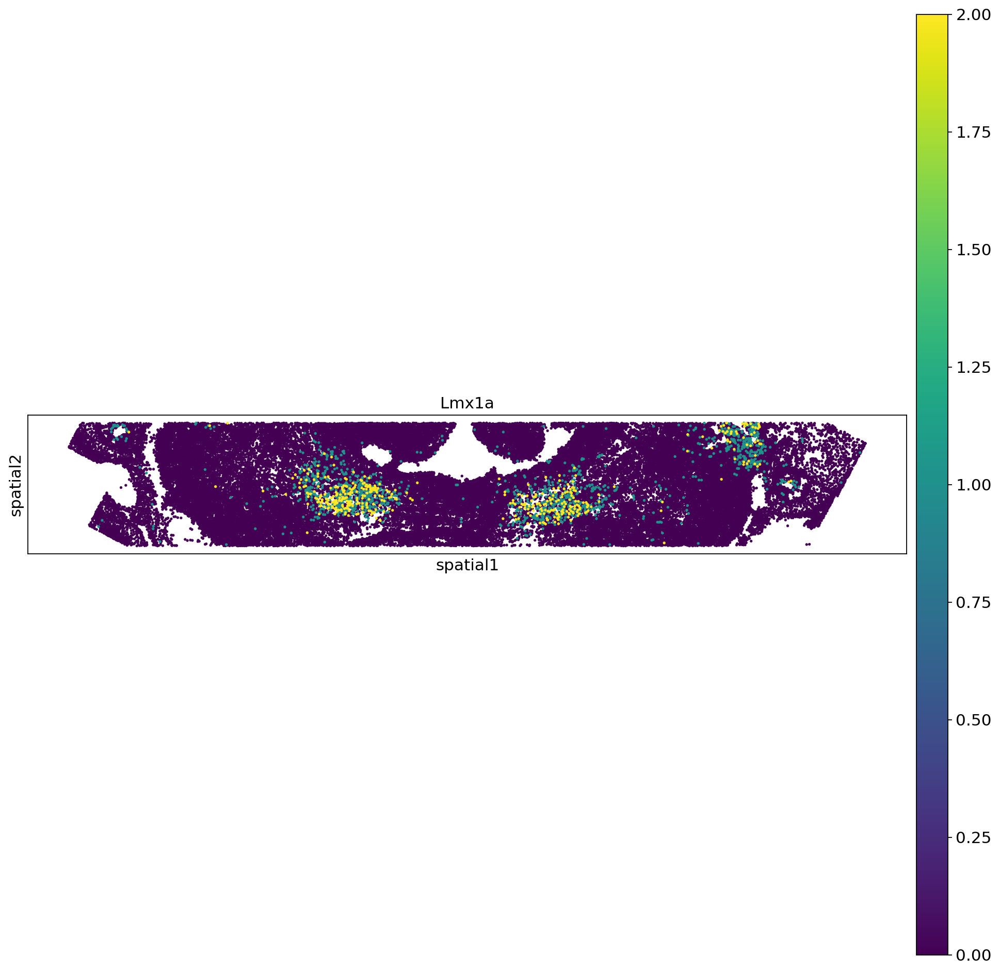

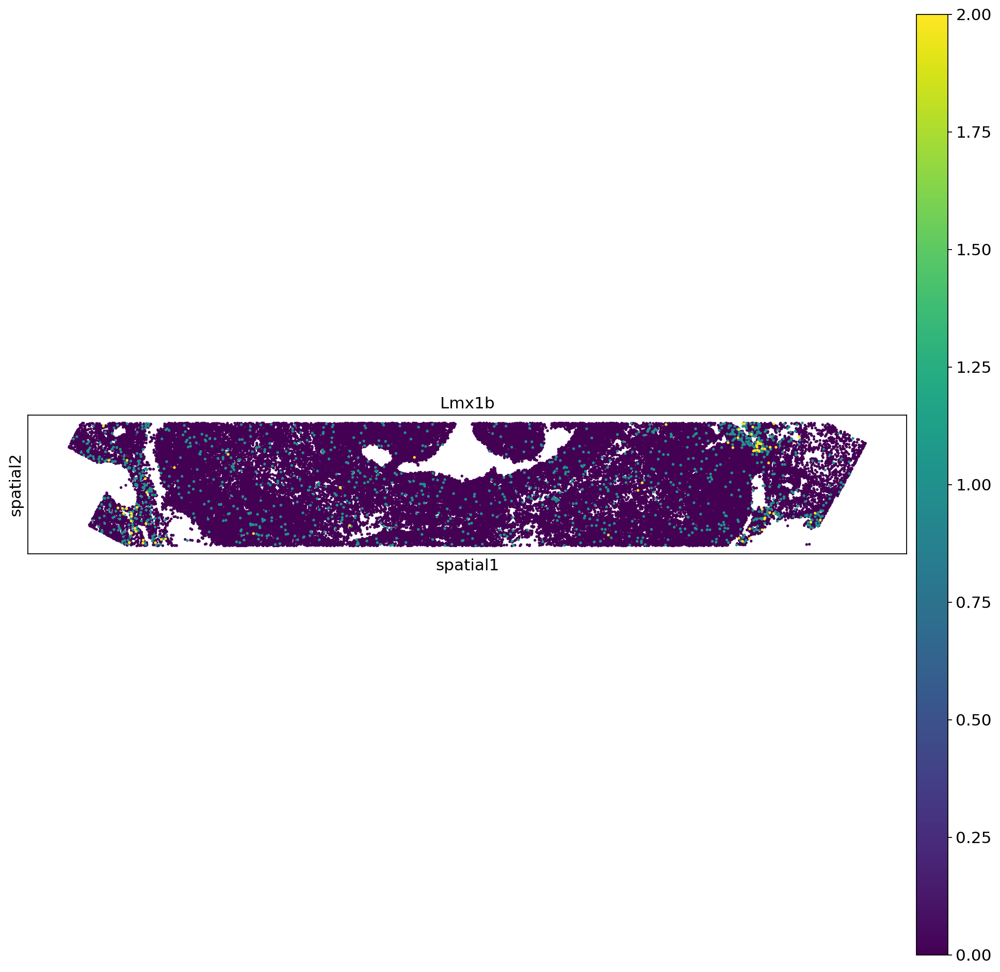

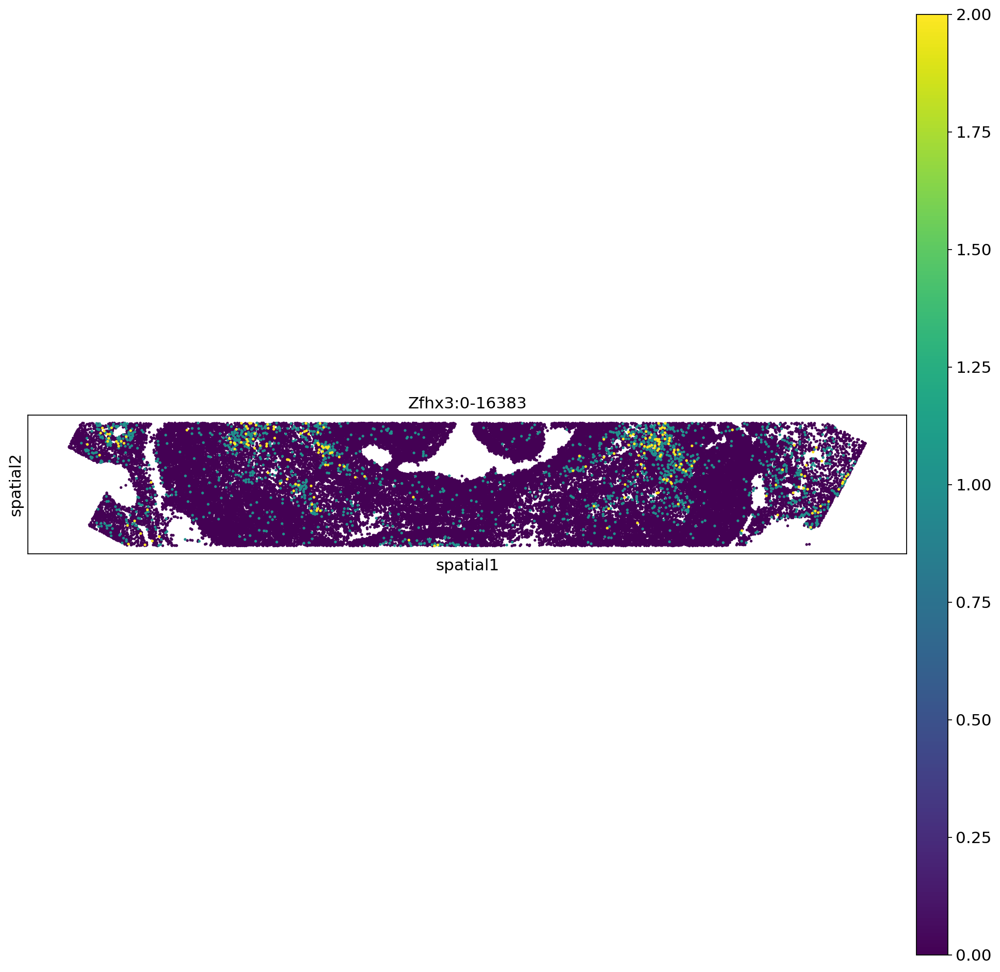

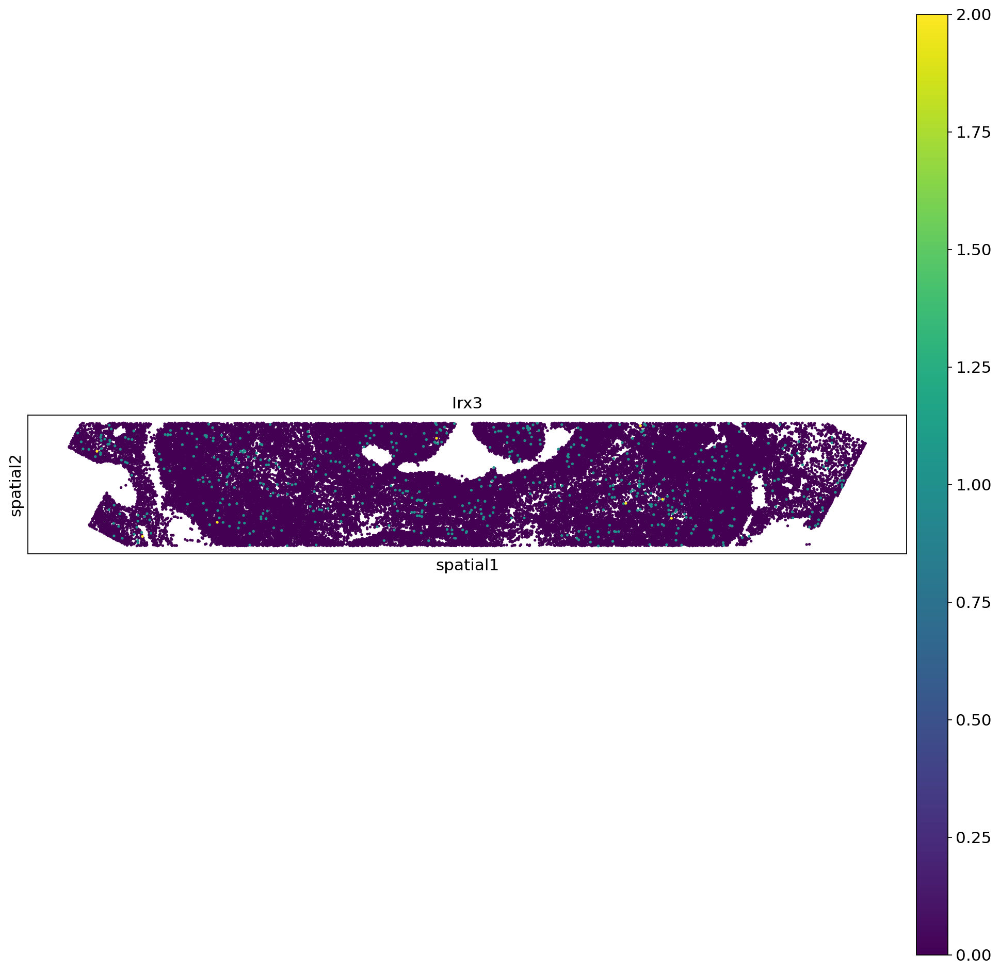

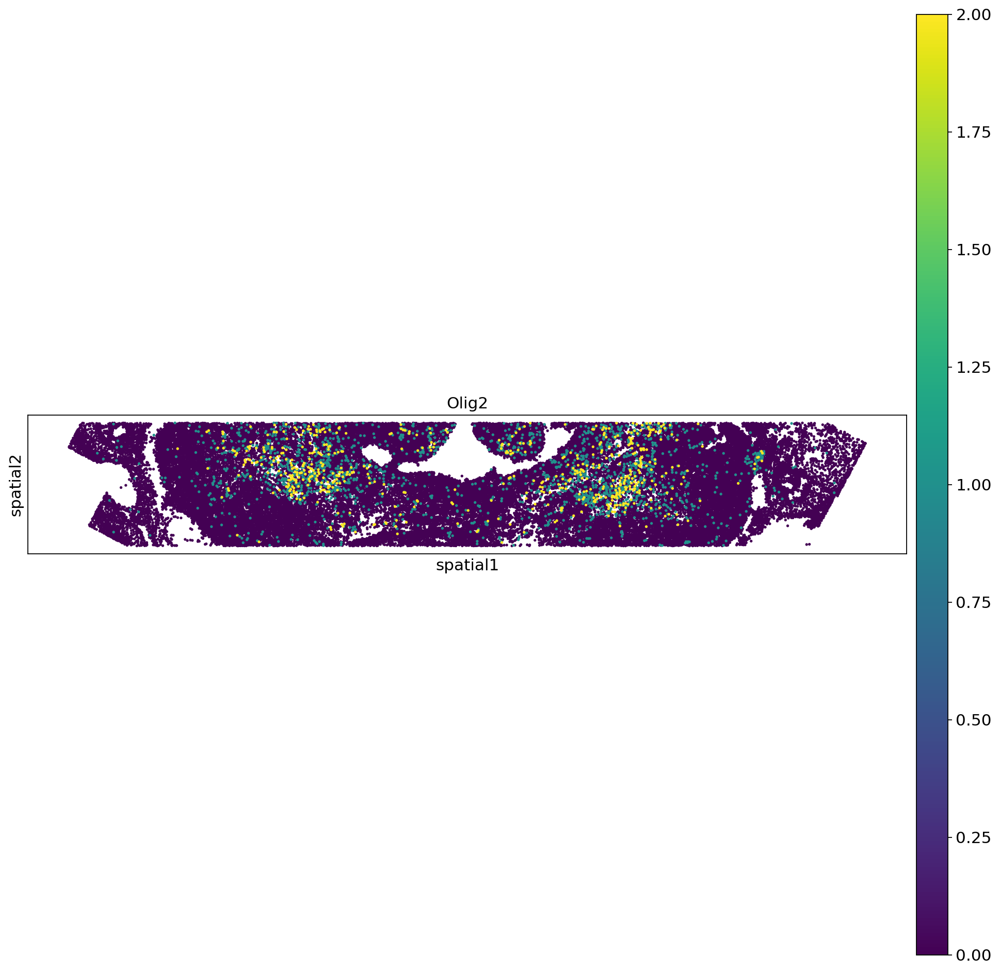

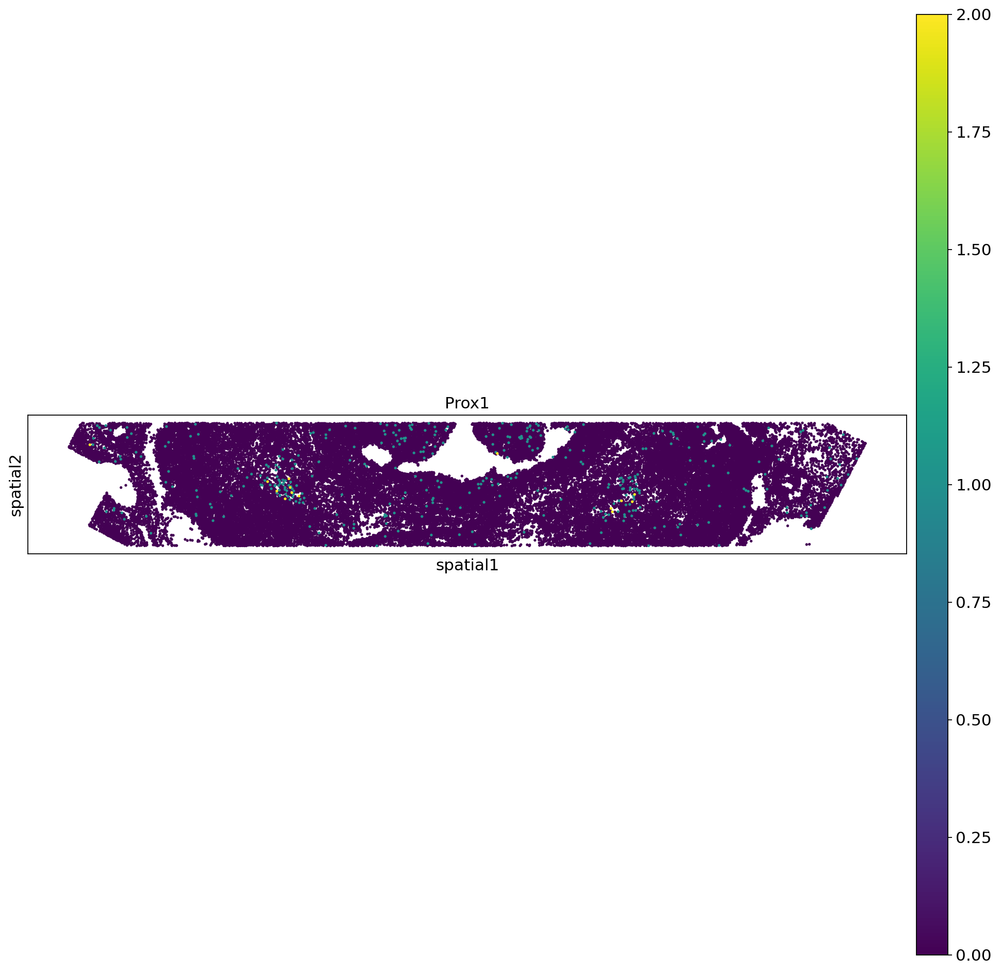

In [6]:
sc.set_figure_params(figsize = (15,15))
sc.pl.spatial(e15_3_corr, color = "Robo3", spot_size = 100, vmax = 2)
sc.pl.spatial(e15_3_corr, color = "Lmx1a", spot_size = 100, vmax = 2)
sc.pl.spatial(e15_3_corr, color = "Lmx1b", spot_size = 100, vmax = 2)
sc.pl.spatial(e15_3_corr, color = "Zfhx3:0-16383", spot_size = 100, vmax = 2)
sc.pl.spatial(e15_3_corr, color = "Irx3", spot_size = 100, vmax = 2)
sc.pl.spatial(e15_3_corr, color = "Olig2", spot_size = 100, vmax = 2)
sc.pl.spatial(e15_3_corr, color = "Prox1", spot_size = 100, vmax = 2)

/tmp/ipykernel_1500928/302803261.py:18: ImplicitModificationWarning: Setting element `.obsm['spatial3d']` of view, initializing view as actual.
  e15_4_corr.obsm['spatial3d'] = np.zeros([len(e15_4_corr),3])


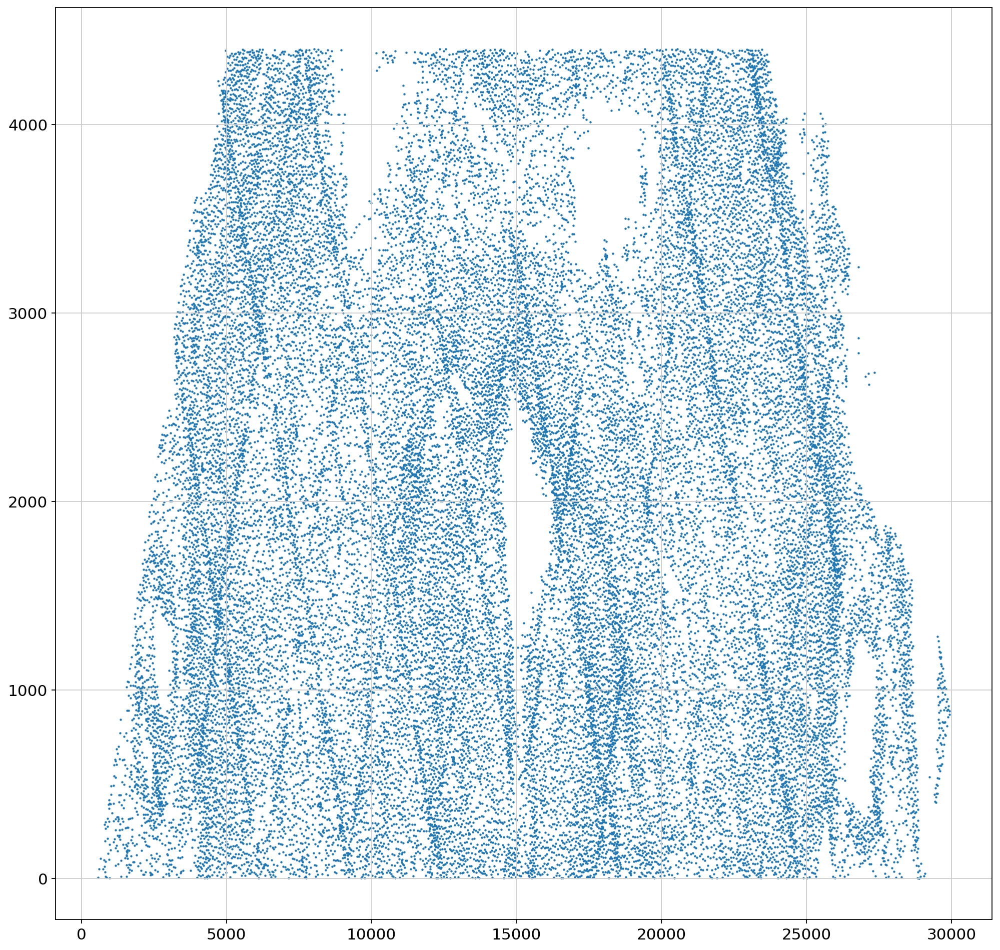

In [7]:
import matplotlib.pyplot as plt

e15_4 = ad.read_h5ad("../../../mouse/e15/ma39_e15_b4/output/adata.h5ad")
e15_4.obs['library_id'] = 'e15_4'
e15_4.obs['timepoint'] = 'e15'
e15_4.obs['batch'] = 'batch2'

e15_4.obsm['spatial'] = rotate_points(e15_4.obsm['spatial'], (-45/180)*3.14)
e15_4_coor = e15_4.obsm['spatial'][e15_4.obsm['spatial'][:,1] <4400]
e15_4_coor = e15_4_coor[e15_4_coor[:,1] >0]
plt.scatter(e15_4_coor[:,0], e15_4_coor[:,1], s=1)

# Convert e13_1_coor to a list of tuples for faster lookups
e15_4_coor_set = {tuple(coord) for coord in e15_4_coor}
mask = np.array([tuple(coord) in e15_4_coor_set for coord in e15_4.obsm['spatial']])
e15_4_corr = e15_4[mask]

e15_4_corr.obsm['spatial3d'] = np.zeros([len(e15_4_corr),3])
x = e15_4_corr.obsm['spatial'][:,0]
y = e15_4_corr.obsm['spatial'][:,1]
e15_4_corr.obsm['spatial'][:,0] = (x - np.min(x))
e15_4_corr.obsm['spatial'][:,1] = (y - np.min(y))#+ 10000*3

In [8]:
adata = ad.concat([e15_1_corr, e15_2_corr,e15_3_corr, e15_4_corr])
# Reset the index and drop the old index column
adata.obs = adata.obs.reset_index(drop=True)


/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


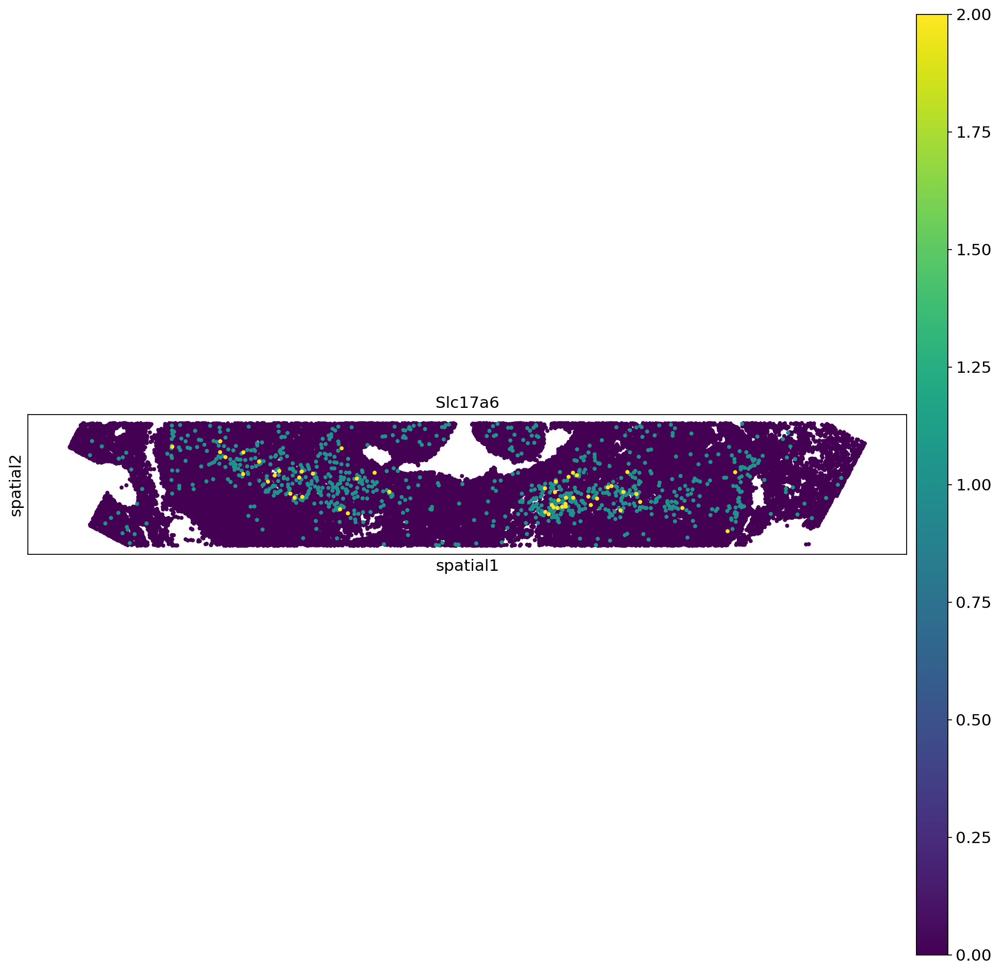

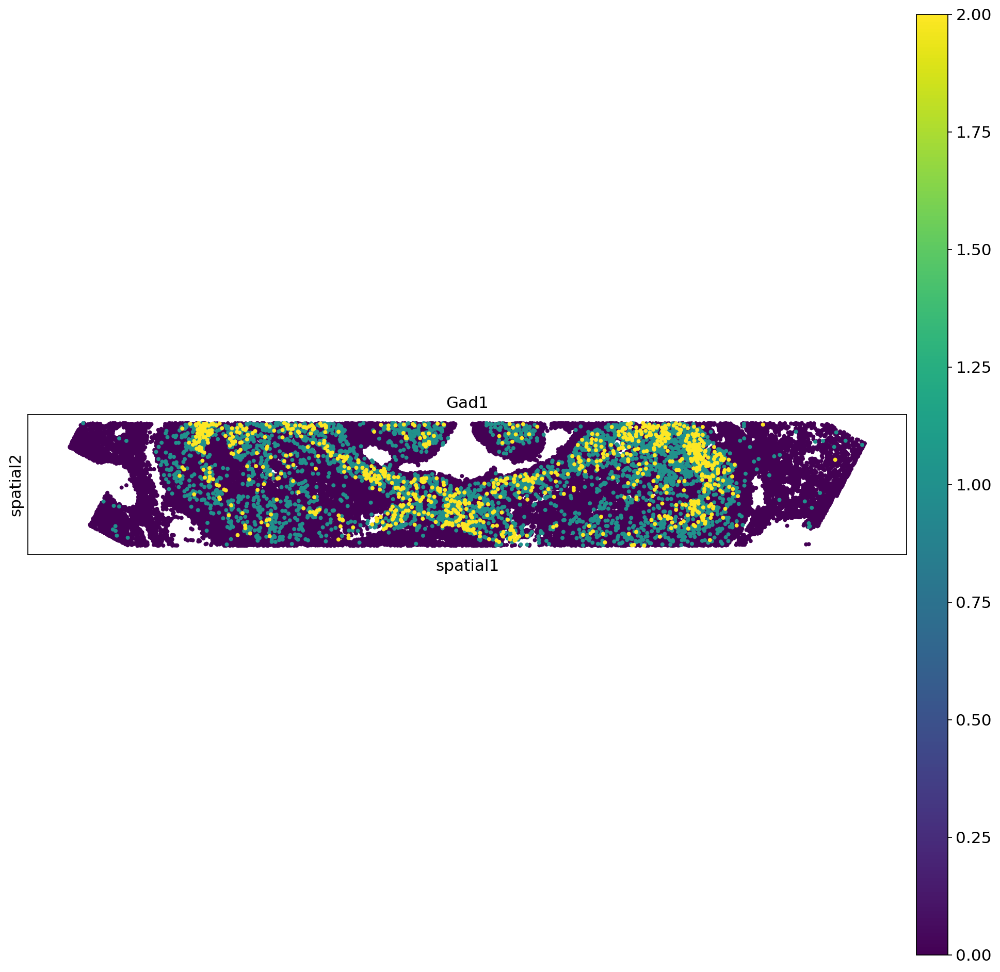

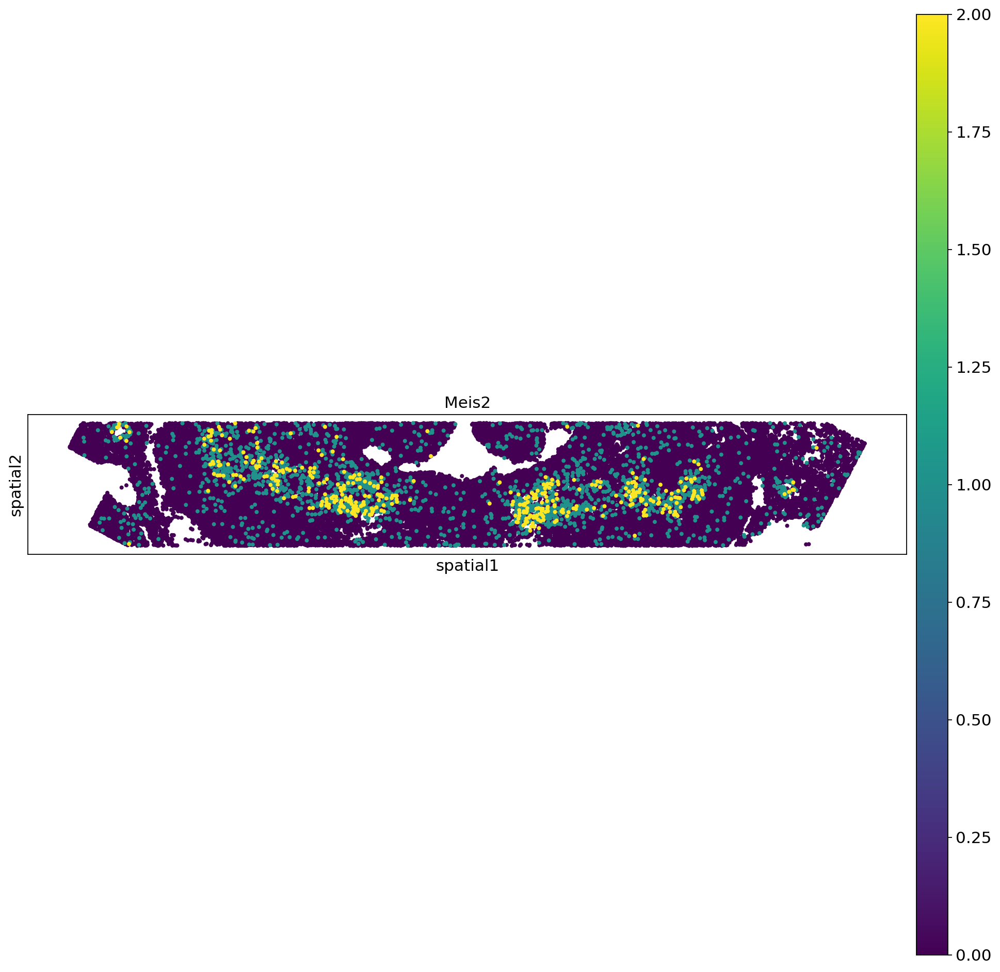

In [10]:
sc.set_figure_params(figsize = (15,15))
sc.pl.spatial(e15_3_corr, color = "Slc17a6", spot_size = 150, vmax = 2)
sc.pl.spatial(e15_3_corr, color = "Gad1", spot_size = 150, vmax = 2)
sc.pl.spatial(e15_3_corr, color = "Meis2", spot_size = 150, vmax = 2)

In [8]:
import scanpy as sc
import numpy as np

# Assuming `adata` is your AnnData object
# Step 1: Identify genes that start with "Zfhx3"
genes_to_combine = [gene for gene in adata.var_names if gene.startswith("Zfhx3")]

if len(genes_to_combine) > 1:
    print(f"Found {len(genes_to_combine)} genes to combine: {genes_to_combine}")

    # Step 2: Select the first "Zfhx3" gene to keep
    first_gene = genes_to_combine[0]

    # Step 3: Add the counts of the other "Zfhx3" genes to the selected one
    for gene in genes_to_combine[1:]:
        # Add the counts from this gene to the first one
        adata[:, first_gene].X += adata[:, gene].X

    # Step 4: Rename the selected gene to "Zfhx3"
    adata.var_names = np.array([("Zfhx3" if gene == first_gene else gene) for gene in adata.var_names])

    # Step 5: Remove the other "Zfhx3" genes from the dataset
    adata = adata[:, ~adata.var_names.isin(genes_to_combine[1:])]  # Remove all but the first "Zfhx3" gene

    print(f"Gene '{first_gene}' combined with {len(genes_to_combine) - 1} other genes and renamed to 'Zfhx3'.")

else:
    print("No genes found starting with 'Zfhx3' or only one gene present.")

# After this, `adata` will have a single gene called "Zfhx3" combining the counts of the original genes.
# Assuming `adata` is your AnnData object

# Step 1: Find genes whose name contains 'no_gene'
gene_mask = adata.var_names.str.contains("no_gene")

# Step 2: Get the expression data for these genes
no_gene_counts = adata[:, gene_mask].X

# Step 3: Identify cells where any of the "no_gene" genes have counts > 1
cells_to_remove = np.any(no_gene_counts > 0, axis=1)

# Step 4: Remove those cells from the AnnData object
adata = adata[~cells_to_remove, :]

# Check the shape of the data after filtering
print(f"Data shape after filtering: {adata.shape}")

Found 2 genes to combine: ['Zfhx3:0-16383', 'Zfhx3:16384-17151']
Gene 'Zfhx3:0-16383' combined with 1 other genes and renamed to 'Zfhx3'.
Data shape after filtering: (147779, 1750)


In [9]:
sc.pp.calculate_qc_metrics(
    adata,percent_top=None, log1p=False, inplace=True
)
sc.pp.calculate_qc_metrics(
    adata,percent_top=None, log1p=False, inplace=True
)
#sc.pp.filter_cells(adata, min_counts=5)
#sc.pp.filter_genes(adata, min_cells=10)


/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/scanpy/preprocessing/_qc.py:141: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[obs_metrics.columns] = obs_metrics
/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


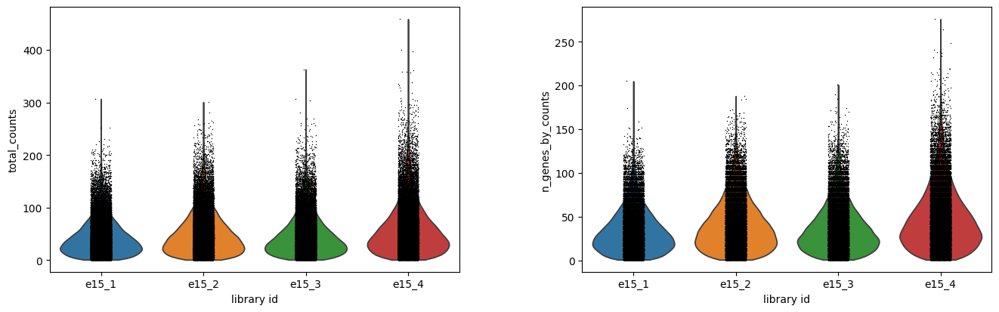

In [10]:
sc.pl.violin(adata, keys=["total_counts", "n_genes_by_counts"], groupby="library_id")

In [10]:
import scanpy as sc
import squidpy as sq
import scipy.sparse as sp

# --- Load your spatial AnnData ---
# Replace with your own dataset
#adata = sq.datasets.visium_hne_adata()


import scanpy as sc

print("save raw counts")
adata.layers["counts"] = adata.X.copy()

print("normalize total")
sc.pp.normalize_total(adata)
adata.layers["normalized"] = adata.X.copy()

print("log transform")
sc.pp.log1p(adata)
adata.layers["lognorm"] = adata.X.copy()   # use this for pseudobulk / correlations

print("highly_variable_genes")
# sc.pp.highly_variable_genes(adata, n_top_genes=500, batch_key="library_id")

print("regress_out")
sc.pp.regress_out(adata, ["total_counts"])
adata.layers["regressed"] = adata.X.copy()

print("scale")
sc.pp.scale(adata, max_value=10)
adata.layers["scaled"] = adata.X.copy()


# PCA for transcriptomic representation
sc.pp.pca(adata)
sc.external.pp.harmony_integrate(adata, 'library_id')


# --- Compute expression-based neighbors ---
sc.pp.neighbors(adata, use_rep="X_pca_harmony")#, n_neighbors=10)  # adjustable

# --- Compute spatial neighbors ---
adata.obsm['generic'] = adata.obsm['spatial']
sq.gr.spatial_neighbors(adata, coord_type="generic", radius=150)  # tune radius to your tissue size

# --- Create hybrid adjacency: weighted sum ---
expr_graph = adata.obsp['connectivities']
spatial_graph = adata.obsp['spatial_connectivities']



/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


save raw counts
normalize total
log transform
highly_variable_genes
regress_out
scale


2026-07-11 20:14:33,518 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-07-11 20:14:44,928 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-07-11 20:14:45,873 - harmonypy - INFO - Iteration 1 of 10
2026-07-11 20:15:45,910 - harmonypy - INFO - Iteration 2 of 10
2026-07-11 20:16:46,076 - harmonypy - INFO - Iteration 3 of 10
2026-07-11 20:17:46,083 - harmonypy - INFO - Iteration 4 of 10
2026-07-11 20:18:04,371 - harmonypy - INFO - Iteration 5 of 10
2026-07-11 20:18:22,598 - harmonypy - INFO - Iteration 6 of 10
2026-07-11 20:18:40,911 - harmonypy - INFO - Iteration 7 of 10
2026-07-11 20:18:59,091 - harmonypy - INFO - Converged after 7 iterations


In [11]:
print("Leiden")

# --- Compute spatial neighbors ---
adata.obsm['generic'] = adata.obsm['spatial']
sq.gr.spatial_neighbors(adata, coord_type="generic", radius=50)  # tune radius to your tissue size

# --- Create hybrid adjacency: weighted sum ---
expr_graph = adata.obsp['connectivities']
spatial_graph = adata.obsp['spatial_connectivities']

# Weight expression vs spatial influence
alpha = 0.8  # higher = more transcriptomic, lower = more spatial
hybrid_graph = expr_graph.multiply(alpha) + spatial_graph.multiply(1 - alpha)

# --- Cluster using hybrid graph ---
#sc.tl.leiden(adata, adjacency=hybrid_graph, key_added='hybrid_leiden', resolution=0.5)

# --- Visualization ---
sc.set_figure_params(figsize=(5, 5))
#sc.pl.umap(adata, color=["hybrid_leiden", "library_id", "batch"], size=5)

Leiden


In [ ]:
sc.tl.leiden(adata, adjacency=hybrid_graph, key_added='hybrid_leiden', resolution=0.5)


/tmp/ipykernel_1168419/1095002708.py:1: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata, adjacency=hybrid_graph, key_added='hybrid_leiden', resolution=0.5)


In [ ]:
sc.set_figure_params(figsize=(15, 5))
for i in np.unique(adata.obs['library_id']):
    sc.pl.spatial(adata[adata.obs['library_id']==i], color='hybrid_leiden', spot_size = 70, vmax=2)

In [ ]:
label_clusters = {
    "0": "Cb",
    "1": "Outside_Cb",
    "2": "GranuleCells",
    "3": "Cb_prog",
    "4": "i1 Neurons"
   # "5": "",

}

adata.obs["cell_types"] = adata.obs['hybrid_leiden'].map(label_clusters)
adata.obs["finer_cell_types"] = adata.obs['hybrid_leiden'].map(label_clusters)

In [ ]:
adata_sub = adata[adata.obs['hybrid_leiden'] == '0']

In [ ]:

# --- Compute expression-based neighbors ---
sc.pp.neighbors(adata_sub, use_rep="X_pca_harmony", n_neighbors=10)  # adjustable

# --- Compute spatial neighbors ---
adata_sub.obsm['generic'] = adata_sub.obsm['spatial']
sq.gr.spatial_neighbors(adata_sub, coord_type="generic", radius=150)  # tune radius to your tissue size

# --- Create hybrid adjacency: weighted sum ---
expr_graph = adata_sub.obsp['connectivities']
spatial_graph = adata_sub.obsp['spatial_connectivities']

# Weight expression vs spatial influence
alpha = 1  # higher = more transcriptomic, lower = more spatial
hybrid_graph = expr_graph.multiply(alpha) + spatial_graph.multiply(1 - alpha)




In [ ]:
# --- Cluster using hybrid graph ---
sc.set_figure_params(figsize = (15,15))
sc.tl.leiden(adata_sub, adjacency=hybrid_graph, key_added='hybrid_leiden', resolution=0.6)
#sc.pl.spatial(adata_sub, color=['hybrid_leiden'], spot_size=100)


In [ ]:
sc.set_figure_params(figsize=(15, 5))
for i in np.unique(adata_sub.obs['library_id']):
    sc.pl.spatial(adata_sub[adata_sub.obs['library_id']==i], color='hybrid_leiden', spot_size = 100, vmax=2)

In [ ]:
label_clusters = {
    "0": "Med",
    "3":"Int/Lat"
    '4': "Interneurons",
    "1": "Purkinje Cells",
    "2": "Interneurons",
    "9": "X_neurons"

}

adata_sub.obs["cell_types"] = adata_sub.obs['hybrid_leiden'].map(label_clusters)
adata_sub.obs["finer_cell_types"] = adata_sub.obs['hybrid_leiden'].map(label_clusters)

/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:461: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:461: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:461: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:461: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:461: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.l

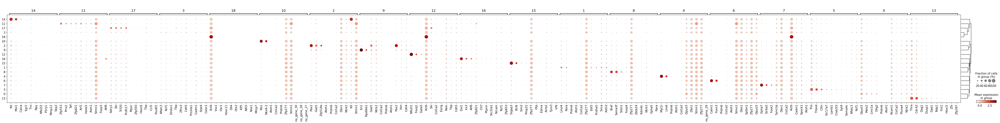

In [20]:
sc.tl.dendrogram(adata_sub, groupby="hybrid_leiden")
sc.tl.rank_genes_groups(adata_sub, 'hybrid_leiden', method='wilcoxon', key_added = "wilcoxon")
#sc.pl.rank_genes_groups_heatmap(adata_crop, n_genes=5, key="wilcoxon", groupby="leiden", show_gene_labels=True, vmax = 3)
sc.pl.rank_genes_groups_dotplot(adata_sub, key="wilcoxon", groupby="hybrid_leiden", n_genes = 10)

In [22]:
adata.write_h5ad("E15_temp_whole.h5ad")

In [23]:
adata_sub.write_h5ad("E15_temp.h5ad")

In [ ]:
adata_sub_cn1 = adata_sub[adata_sub.obs['hybrid_leiden'].isin(['0', '3'])]

In [22]:

# --- Compute expression-based neighbors ---
sc.pp.neighbors(adata_sub_cn1, use_rep="X_pca_harmony", n_neighbors=10)  # adjustable

# --- Compute spatial neighbors ---
adata_sub_cn1.obsm['generic'] = adata_sub_cn1.obsm['spatial']
sq.gr.spatial_neighbors(adata_sub_cn1, coord_type="generic", radius=150)  # tune radius to your tissue size

# --- Create hybrid adjacency: weighted sum ---
expr_graph = adata_sub_cn1.obsp['connectivities']
spatial_graph = adata_sub_cn1.obsp['spatial_connectivities']

# Weight expression vs spatial influence
alpha = 0.8  # higher = more transcriptomic, lower = more spatial
hybrid_graph = expr_graph.multiply(alpha) + spatial_graph.multiply(1 - alpha)




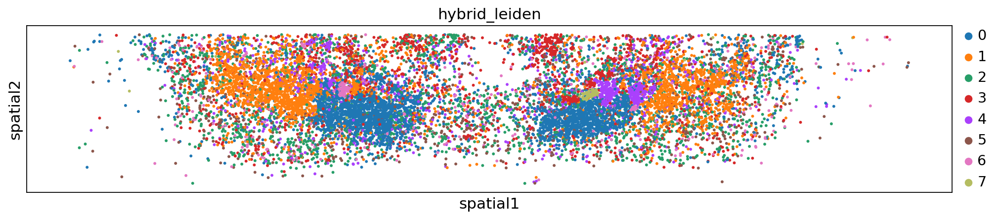

In [23]:
sc.set_figure_params(figsize = (15,15))
sc.tl.leiden(adata_sub_cn1, adjacency=hybrid_graph, key_added='hybrid_leiden', resolution=0.8)
sc.pl.spatial(adata_sub_cn1, color=['hybrid_leiden'], spot_size=100)

/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:461: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:461: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:461: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:461: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:461: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.l

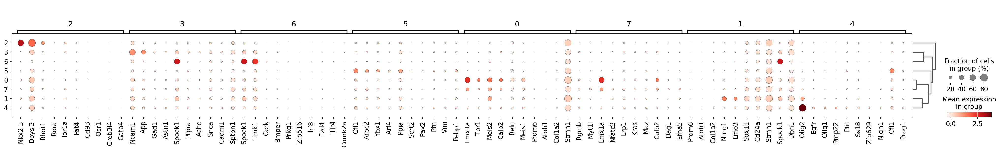

In [24]:
sc.tl.dendrogram(adata_sub_cn1, groupby="hybrid_leiden")
sc.tl.rank_genes_groups(adata_sub_cn1, 'hybrid_leiden', method='wilcoxon', key_added = "wilcoxon")
#sc.pl.rank_genes_groups_heatmap(adata_crop, n_genes=5, key="wilcoxon", groupby="leiden", show_gene_labels=True, vmax = 3)
sc.pl.rank_genes_groups_dotplot(adata_sub_cn1, key="wilcoxon", groupby="hybrid_leiden", n_genes = 10)

In [25]:
label_clusters = {
    "0": "Med",
    "7": "Med",
    "1": "Lat",
    "4": "Int"

}

adata_sub_cn1.obs["cell_types"] = adata_sub_cn1.obs['hybrid_leiden'].map(label_clusters)
adata_sub_cn1.obs["finer_cell_types"] = adata_sub_cn1.obs['hybrid_leiden'].map(label_clusters)

In [26]:
adata_sub_cn2 = adata_sub_cn1[adata_sub_cn1.obs['hybrid_leiden'].isin(['0', '7'])]

In [27]:

# --- Compute expression-based neighbors ---
sc.pp.neighbors(adata_sub_cn2, use_rep="X_pca_harmony", n_neighbors=10)  # adjustable

# --- Compute spatial neighbors ---
adata_sub_cn2.obsm['generic'] = adata_sub_cn2.obsm['spatial']
sq.gr.spatial_neighbors(adata_sub_cn2, coord_type="generic", radius=150)  # tune radius to your tissue size

# --- Create hybrid adjacency: weighted sum ---
expr_graph = adata_sub_cn2.obsp['connectivities']
spatial_graph = adata_sub_cn2.obsp['spatial_connectivities']

# Weight expression vs spatial influence
alpha = 0.9 # higher = more transcriptomic, lower = more spatial
hybrid_graph = expr_graph.multiply(alpha) + spatial_graph.multiply(1 - alpha)




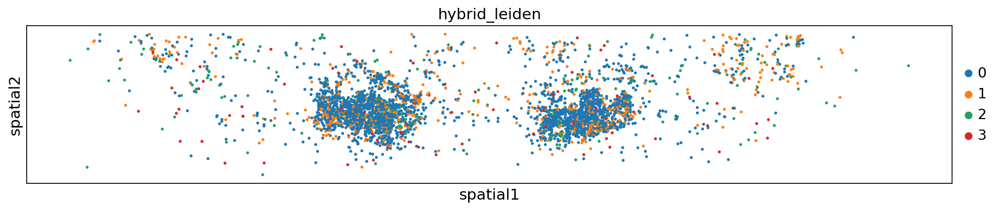

In [28]:
sc.set_figure_params(figsize = (15,15))
sc.tl.leiden(adata_sub_cn2, adjacency=hybrid_graph, key_added='hybrid_leiden', resolution=0.5)
sc.pl.spatial(adata_sub_cn2, color=['hybrid_leiden'], spot_size=100)

/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:461: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:461: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:461: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:461: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(


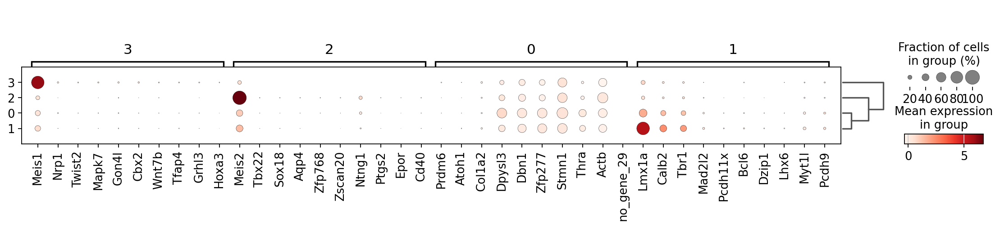

In [29]:
sc.tl.dendrogram(adata_sub_cn2, groupby="hybrid_leiden")
sc.tl.rank_genes_groups(adata_sub_cn2, 'hybrid_leiden', method='wilcoxon', key_added = "wilcoxon")
#sc.pl.rank_genes_groups_heatmap(adata_crop, n_genes=5, key="wilcoxon", groupby="leiden", show_gene_labels=True, vmax = 3)
sc.pl.rank_genes_groups_dotplot(adata_sub_cn2, key="wilcoxon", groupby="hybrid_leiden", n_genes = 10)

In [30]:
label_clusters = {
    "0": "Med1",
    "1": "Med2",
    "2": "Med3",
    "3": "Med4"

}

adata_sub_cn2.obs["cell_types"] = adata_sub_cn2.obs['hybrid_leiden'].map(label_clusters)
adata_sub_cn2.obs["finer_cell_types"] = adata_sub_cn2.obs['hybrid_leiden'].map(label_clusters)

In [31]:
adata_sub_cn3 = adata_sub_cn1[adata_sub_cn1.obs['hybrid_leiden'].isin(['1', '4'])]

In [32]:

# --- Compute expression-based neighbors ---
sc.pp.neighbors(adata_sub_cn3, use_rep="X_pca_harmony", n_neighbors=10)  # adjustable

# --- Compute spatial neighbors ---
adata_sub_cn3.obsm['generic'] = adata_sub_cn3.obsm['spatial']
sq.gr.spatial_neighbors(adata_sub_cn3, coord_type="generic", radius=150)  # tune radius to your tissue size

# --- Create hybrid adjacency: weighted sum ---
expr_graph = adata_sub_cn3.obsp['connectivities']
spatial_graph = adata_sub_cn3.obsp['spatial_connectivities']

# Weight expression vs spatial influence
alpha = 0.95 # higher = more transcriptomic, lower = more spatial
hybrid_graph = expr_graph.multiply(alpha) + spatial_graph.multiply(1 - alpha)




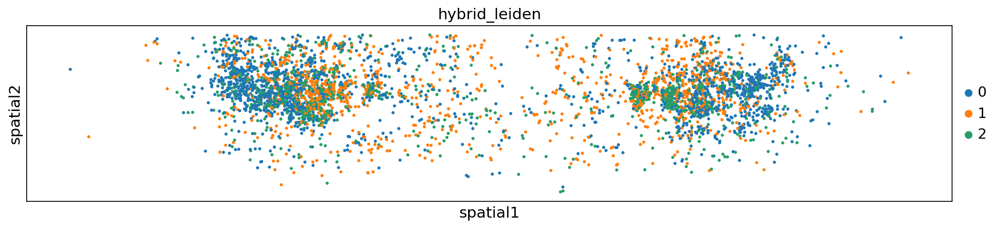

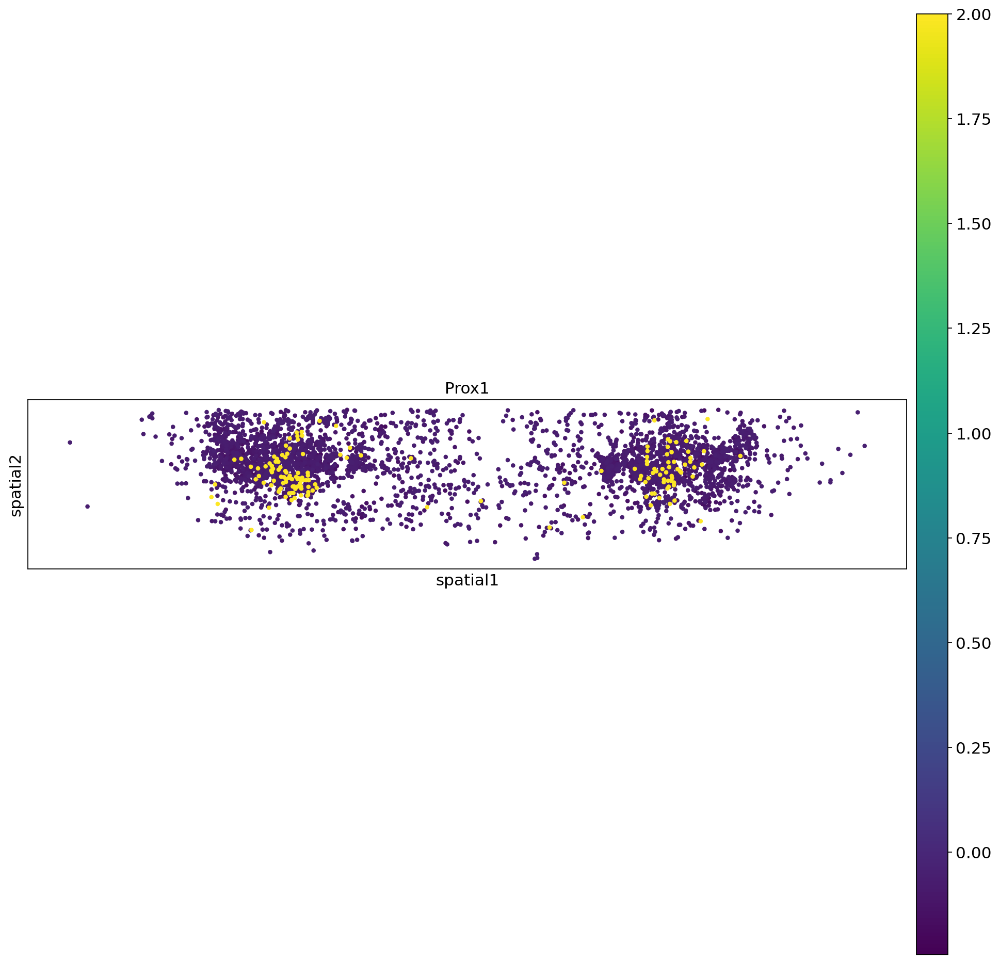

In [33]:
sc.set_figure_params(figsize = (15,15))
sc.tl.leiden(adata_sub_cn3, adjacency=hybrid_graph, key_added='hybrid_leiden', resolution=0.5)
sc.pl.spatial(adata_sub_cn3, color=['hybrid_leiden'], spot_size=100)
sc.pl.spatial(adata_sub_cn3, color=['Prox1'], spot_size=150, vmax = 2)

/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:461: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:461: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:461: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(


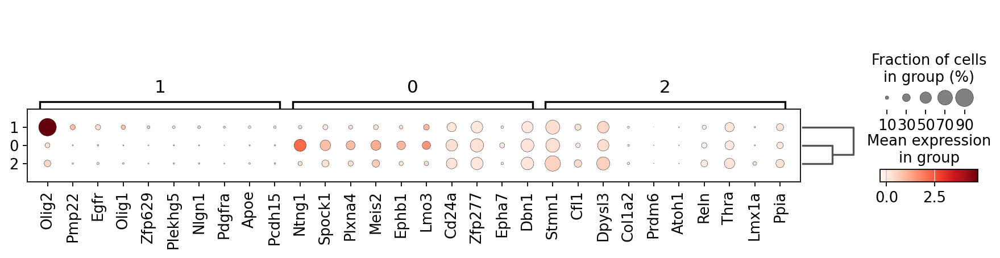

In [34]:
sc.tl.dendrogram(adata_sub_cn3, groupby="hybrid_leiden")
sc.tl.rank_genes_groups(adata_sub_cn3, 'hybrid_leiden', method='wilcoxon', key_added = "wilcoxon")
#sc.pl.rank_genes_groups_heatmap(adata_crop, n_genes=5, key="wilcoxon", groupby="leiden", show_gene_labels=True, vmax = 3)
sc.pl.rank_genes_groups_dotplot(adata_sub_cn3, key="wilcoxon", groupby="hybrid_leiden", n_genes = 10)

In [35]:
label_clusters = {
    "0": "IntA/Lat",
    "1": "IntP",
    "2": "IntP",

}

adata_sub_cn3.obs["cell_types"] = adata_sub_cn3.obs['hybrid_leiden'].map(label_clusters)
adata_sub_cn3.obs["finer_cell_types"] = adata_sub_cn3.obs['hybrid_leiden'].map(label_clusters)

In [36]:
adata_sub_cn4 = adata_sub_cn3[adata_sub_cn3.obs['hybrid_leiden'].isin(['0'])]

In [37]:

# --- Compute expression-based neighbors ---
sc.pp.neighbors(adata_sub_cn4, use_rep="X_pca_harmony", n_neighbors=10)  # adjustable

# --- Compute spatial neighbors ---
adata_sub_cn4.obsm['generic'] = adata_sub_cn4.obsm['spatial']
sq.gr.spatial_neighbors(adata_sub_cn4, coord_type="generic", radius=150)  # tune radius to your tissue size

# --- Create hybrid adjacency: weighted sum ---
expr_graph = adata_sub_cn4.obsp['connectivities']
spatial_graph = adata_sub_cn4.obsp['spatial_connectivities']

# Weight expression vs spatial influence
alpha = 0.95 # higher = more transcriptomic, lower = more spatial
hybrid_graph = expr_graph.multiply(alpha) + spatial_graph.multiply(1 - alpha)




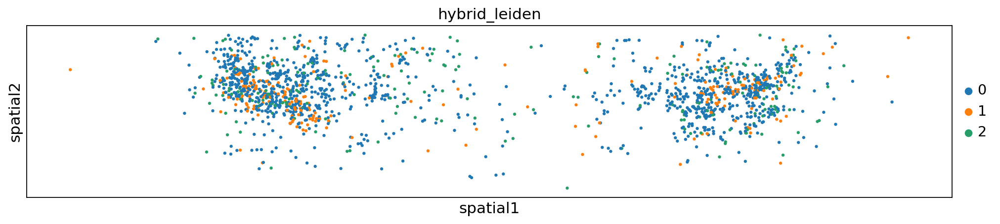

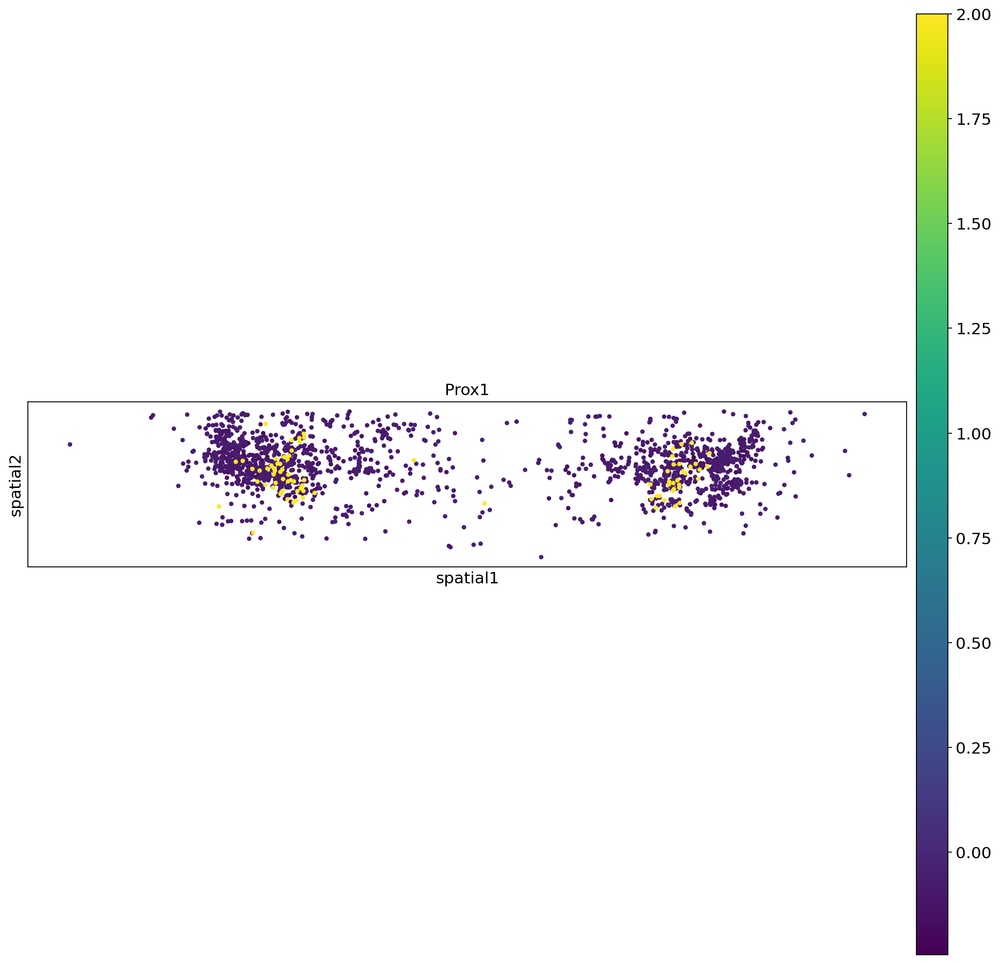

In [38]:
sc.set_figure_params(figsize = (15,15))
sc.tl.leiden(adata_sub_cn4, adjacency=hybrid_graph, key_added='hybrid_leiden', resolution=0.5)
sc.pl.spatial(adata_sub_cn4, color=['hybrid_leiden'], spot_size=100)
sc.pl.spatial(adata_sub_cn4, color=['Prox1'], spot_size=150, vmax = 2)

/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:461: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:461: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:461: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(


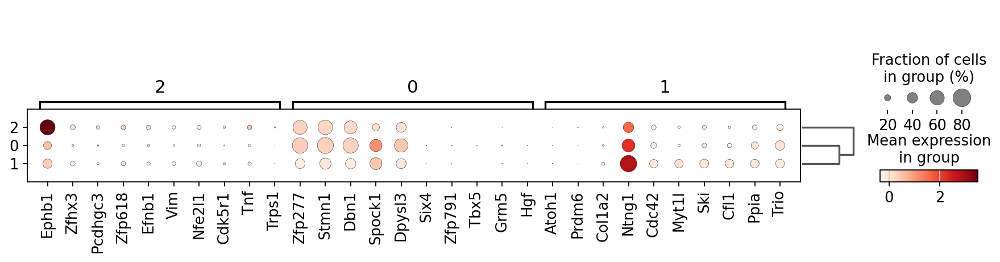

In [39]:
sc.tl.dendrogram(adata_sub_cn4, groupby="hybrid_leiden")
sc.tl.rank_genes_groups(adata_sub_cn4, 'hybrid_leiden', method='wilcoxon', key_added = "wilcoxon")
#sc.pl.rank_genes_groups_heatmap(adata_crop, n_genes=5, key="wilcoxon", groupby="leiden", show_gene_labels=True, vmax = 3)
sc.pl.rank_genes_groups_dotplot(adata_sub_cn4, key="wilcoxon", groupby="hybrid_leiden", n_genes = 10)

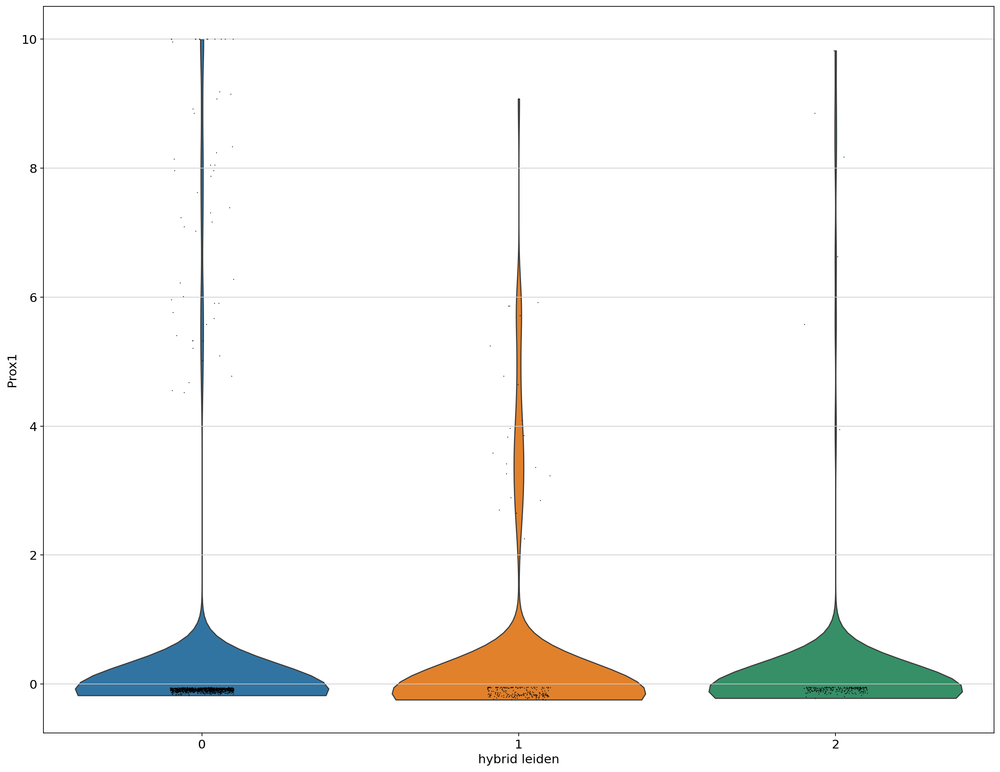

In [40]:
sc.pl.violin(adata_sub_cn4, groupby = "hybrid_leiden", keys = "Prox1")

In [41]:
label_clusters = {
    "0": "Lat",
    "1": "IntA",
    "2": "Lat",

}

adata_sub_cn4.obs["cell_types"] = adata_sub_cn4.obs['hybrid_leiden'].map(label_clusters)
adata_sub_cn4.obs["finer_cell_types"] = adata_sub_cn4.obs['hybrid_leiden'].map(label_clusters)

In [1]:
import scanpy as sc
adata = sc.read_h5ad("E15_temp_whole.h5ad")
adata_sub = sc.read_h5ad("E15_temp.h5ad")

In [2]:
import gc
import pandas as pd


# Make sure cell indices are strings
adata.obs_names = adata.obs_names.astype(str)
adata_sub.obs_names = adata_sub.obs_names.astype(str)


# Ensure the annotation column exists in the full object
if "finer_cell_types" not in adata.obs.columns:
    adata.obs["finer_cell_types"] = pd.NA


# Find cells shared between adata_sub and adata
common_cells = adata.obs_names.intersection(adata_sub.obs_names)

print(f"Cells in adata_sub: {adata_sub.n_obs}")
print(f"Cells matching adata: {len(common_cells)}")
print(f"Cells not matching adata: {adata_sub.n_obs - len(common_cells)}")


# Avoid categorical assignment errors
adata.obs["finer_cell_types"] = (
    adata.obs["finer_cell_types"]
    .astype(object)
)

sub_annotations = (
    adata_sub.obs
    .loc[common_cells, "finer_cell_types"]
    .astype(object)
)


# Transfer only non-missing annotations from adata_sub
valid_annotations = (
    sub_annotations.notna()
    & ~sub_annotations.astype(str).isin(
        ["NA", "nan", "None", "Other"]
    )
)

cells_to_update = sub_annotations.index[valid_annotations]

adata.obs.loc[
    cells_to_update,
    "finer_cell_types"
] = sub_annotations.loc[cells_to_update].values


# Keep only cells with valid finer-cell-type annotations
valid_cells = (
    adata.obs["finer_cell_types"].notna()
    & ~adata.obs["finer_cell_types"].astype(str).isin(
        ["NA", "nan", "None", "Other"]
    )
)

# This is a view and therefore avoids immediately copying several GB
adata_all = adata[valid_cells]


# Optionally convert back to categorical
adata.obs["finer_cell_types"] = pd.Categorical(
    adata.obs["finer_cell_types"]
)

gc.collect()


print(adata_all)
print("\nCell-type counts:")
print(
    adata_all.obs["finer_cell_types"]
    .value_counts()
)

Cells in adata_sub: 78398
Cells matching adata: 78398
Cells not matching adata: 0
View of AnnData object with n_obs × n_vars = 147667 × 1750
    obs: 'cell_number', 'library_id', 'timepoint', 'batch', 'n_genes_by_counts', 'total_counts', 'hybrid_leiden', 'cell_types', 'finer_cell_types'
    var: 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'mean', 'std'
    uns: 'hybrid_leiden', 'log1p', 'neighbors', 'pca', 'spatial_neighbors'
    obsm: 'X_pca', 'X_pca_harmony', 'generic', 'spatial', 'spatial3d'
    varm: 'PCs'
    layers: 'counts', 'lognorm', 'normalized', 'regressed', 'scaled'
    obsp: 'connectivities', 'distances', 'spatial_connectivities', 'spatial_distances'

Cell-type counts:
finer_cell_types
Cb                31485
Outside_Cb        29631
GranuleCells      16172
Cb_prog           15588
Purkinje Cells     9585
Lat                9264
i1 Neurons         7878
Interneurons       7792
Med                5676
IntP               5674
Med1               

In [3]:
del adata
del adata_sub

In [4]:
adata_all

View of AnnData object with n_obs × n_vars = 147667 × 1750
    obs: 'cell_number', 'library_id', 'timepoint', 'batch', 'n_genes_by_counts', 'total_counts', 'hybrid_leiden', 'cell_types', 'finer_cell_types'
    var: 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'mean', 'std'
    uns: 'hybrid_leiden', 'log1p', 'neighbors', 'pca', 'spatial_neighbors'
    obsm: 'X_pca', 'X_pca_harmony', 'generic', 'spatial', 'spatial3d'
    varm: 'PCs'
    layers: 'counts', 'lognorm', 'normalized', 'regressed', 'scaled'
    obsp: 'connectivities', 'distances', 'spatial_connectivities', 'spatial_distances'

In [ ]:
sc.set_figure_params(figsize = (25,25))

sc.pl.spatial(adata_all, color='finer_cell_types', spot_size = 100)


/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/scanpy/plotting/_utils.py:487: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


In [ ]:
sc.set_figure_params(figsize = (25,25))

sc.pl.spatial(adata_all, color='finer_cell_types', spot_size = 70)


In [6]:
import numpy as np
np.unique(adata_all.obs["finer_cell_types"])

array(['Cb', 'Cb_prog', 'GranuleCells', 'IntA', 'IntP', 'Interneurons',
       'Lat', 'Med', 'Med1', 'Med2', 'Outside_Cb', 'Purkinje Cells',
       'X_neurons', 'i1 Neurons'], dtype=object)

In [18]:
excitatory = [
       'IntA', 'IntP', 'Lat', 'Med1', 'Med2']

inhibitory = [ 'Interneurons', 'Purkinje Cells',
       'X_neurons', 'i1 Neurons']

In [8]:
del adata
del adata_sub

NameError: name 'adata' is not defined

In [19]:
# 1) Define which cell types you want to keep

# 2) Create or copy a column called "excitatory"
adata_all.obs["excitatory"] = adata_all.obs["finer_cell_types"]
adata_all.obs["inhibitory"] = adata_all.obs["finer_cell_types"]
print('hi!')
# 3) For any cell whose type is NOT in allowed_types, set that entry to NaN
mask = ~adata_all.obs["excitatory"].isin(excitatory)
adata_all.obs.loc[mask, "excitatory"] = np.nan

mask = ~adata_all.obs["inhibitory"].isin(inhibitory)
adata_all.obs.loc[mask, "inhibitory"] = np.nan


hi!


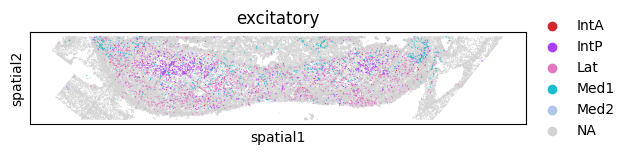

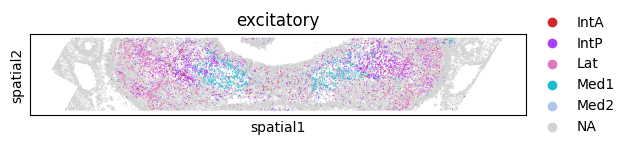

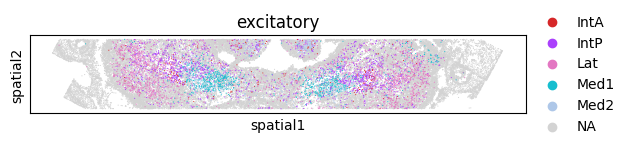

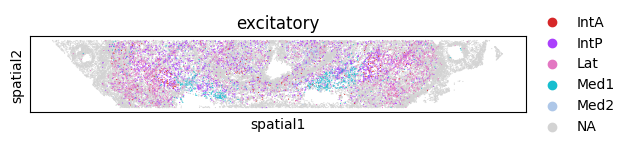

In [22]:
for i in np.unique(adata_all.obs['library_id']):
    sc.pl.spatial(adata_all[adata_all.obs['library_id'] == i], color='excitatory', spot_size = 70)


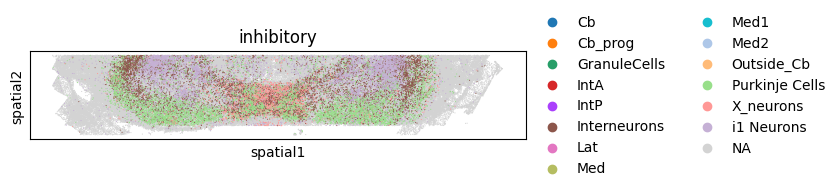

In [16]:
sc.pl.spatial(adata_all, color='inhibitory', spot_size = 70)


In [21]:
adata_all.write_h5ad("adata_objects/e15_celltypes_spatialclustering.h5ad")

In [ ]:
import numpy as np

# initialize with 'Other' or NaN
adata_sub_cn.obs['finer_cell_types'] = np.nan

# Condition 1: GeneA > 2 → "A"
adata_sub_cn.obs.loc[np.asarray(adata_sub_cn[:, "Ntng1"].X).ravel() > 1, 'finer_cell_types'] = "Lat"

adata_sub_cn.obs.loc[np.asarray(adata_sub_cn[:, "Olig2"].X).ravel() > 1, 'finer_cell_types'] = "IntP"

adata_sub_cn.obs.loc[np.asarray(adata_sub_cn[:, "Lmo3"].X).ravel() > 1, 'finer_cell_types'] = "IntP"


# Condition 2: GeneB > 2 → "C"
adata_sub_cn.obs.loc[np.asarray(adata_sub_cn[:, "Epha7"].X).ravel() > 1, 'finer_cell_types'] = "Lat"

adata_sub_cn.obs.loc[np.asarray(adata_sub_cn[:, "Prox1"].X).ravel() > 1, 'finer_cell_types'] = "IntA"

adata_sub_cn.obs.loc[np.asarray(adata_sub_cn[:, "Lmx1a"].X).ravel() > 1, 'finer_cell_types'] = "Med1"

adata_sub_cn.obs.loc[np.asarray(adata_sub_cn[:, "Calb2"].X).ravel() > 1, 'finer_cell_types'] = "Med2"
adata_sub_cn.obs.loc[np.asarray(adata_sub_cn[:, "Prox1"].X).ravel() > 1, 'finer_cell_types'] = "IntA"

